# Dar_048 - Dust: current uncertainty, impact classes, thresholds and time

## Questions
- How do signed, background-subtracted current and reported standard deviations affect supported evidence?
- How do recorded impact mass, mass threshold, uncertainty and saturation differ across native quality classes?
- Which UTC calendar summaries are supported by the actual short historical mission span?
- Do original current summaries still match Dar_044, and what can guide Stage 4?

All 36 selected LDEX current/mass tables are read. Mass numerical support is **not** reliable-event classification; no class-number ordering is assumed. Catalog record counts are **not** exposure-corrected rates. No fabricated year-plus history, lunar-season claim, surface loading or equipment-degradation conversion is made.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'env_algo_task/EDA').is_dir())
sys.path.insert(0,str(root/'env_algo_task/EDA/Moon/Stage3_Requirements'))
from stage3_dust_eda import execute

## Execute the complete selected cohort
Receipt/hash-checked science and native field descriptions are saved with each run. The full execution follows separate small-sample validation.

In [2]:
folder,findings=execute(sample=False)
display(findings)

{
  "subject": "dust",
  "sample": false,
  "analysed_files": 36,
  "current_records": 677271,
  "mass_catalog_records": 441166,
  "current_recorded_dates": 166,
  "mass_recorded_dates": 166,
  "ambiguous_current_clock_records": 0,
  "ambiguous_mass_clock_records": 0,
  "numerically_supported_mass_records": 437451,
  "numerical_mass_below_native_threshold": 9041,
  "time_start": "2013-10-24 17:43:38.548000+00:00",
  "time_stop": "2014-04-18 04:30:16.698000+00:00",
  "tables": {
    "current_daily_context": 1494,
    "current_uncertainty_by_file": 54,
    "event_class_summary": 14,
    "event_class_daily_records": 928,
    "mass_threshold_summary": 84,
    "calendar_context": 663,
    "matched_January_December_years": 66,
    "field_metadata": 306,
    "crosscheck_Dar044": 498,
    "stage4_dust_proposals": 5
  },
  "time_contract": "UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=Jan-Apr/May-Aug/Sep-Dec; DJF/MAM/JJA/SON are calendar

{'subject': 'dust',
 'sample': False,
 'analysed_files': 36,
 'current_records': 677271,
 'mass_catalog_records': 441166,
 'current_recorded_dates': 166,
 'mass_recorded_dates': 166,
 'ambiguous_current_clock_records': 0,
 'ambiguous_mass_clock_records': 0,
 'numerically_supported_mass_records': 437451,
 'numerical_mass_below_native_threshold': 9041,
 'time_start': '2013-10-24 17:43:38.548000+00:00',
 'time_stop': '2014-04-18 04:30:16.698000+00:00',
 'tables': {'current_daily_context': 1494,
  'current_uncertainty_by_file': 54,
  'event_class_summary': 14,
  'event_class_daily_records': 928,
  'mass_threshold_summary': 84,
  'calendar_context': 663,
  'matched_January_December_years': 66,
  'field_metadata': 306,
  'crosscheck_Dar044': 498,
  'stage4_dust_proposals': 5},
 'time_contract': 'UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=Jan-Apr/May-Aug/Sep-Dec; DJF/MAM/JJA/SON are calendar labels only, not lunar seasons',
 'base_co

## Current, background and reported uncertainty
Signed current is retained; negative background-subtracted estimates are not negative physical deposition. Reported standard deviation is not automatically standard error or a confidence interval. Value/STD is a descriptive ratio, not an adopted detection test.

,file,quantity,records,finite_value_records,nonnegative_uncertainty_supported,negative_value_records,zero_uncertainty_records,median_std,maximum_current_minus_signal_background_residual,interpretation
0,current_13297_13304.tab,CURRENT,3764,3764,3764,16,0,23565.0,9000.0,"reported standard deviation, not automatically..."
1,current_13297_13304.tab,SIGNAL,3764,3764,3764,0,0,20345.0,9000.0,"reported standard deviation, not automatically..."
2,current_13297_13304.tab,BACKGROUND,3764,3764,3764,0,0,10915.0,9000.0,"reported standard deviation, not automatically..."
3,current_13305_13314.tab,CURRENT,12992,12992,12992,361,0,14040.0,6600.0,"reported standard deviation, not automatically..."
4,current_13305_13314.tab,SIGNAL,12992,12992,12992,0,0,11265.0,6600.0,"reported standard deviation, not automatically..."
5,current_13305_13314.tab,BACKGROUND,12992,12992,12992,0,0,8197.0,6600.0,"reported standard deviation, not automatically..."
6,current_13315_13324.tab,CURRENT,28033,28033,28033,823,0,26510.0,9146.0,"reported standard deviation, not automatically..."
7,current_13315_13324.tab,SIGNAL,28033,28033,28033,0,0,22380.0,9146.0,"reported standard deviation, not automatically..."
8,current_13315_13324.tab,BACKGROUND,28033,28033,28033,0,0,11690.0,9146.0,"reported standard deviation, not automatically..."
9,current_13325_13334.tab,CURRENT,44888,44888,44888,941,0,27525.0,10000.0,"reported standard deviation, not automatically..."


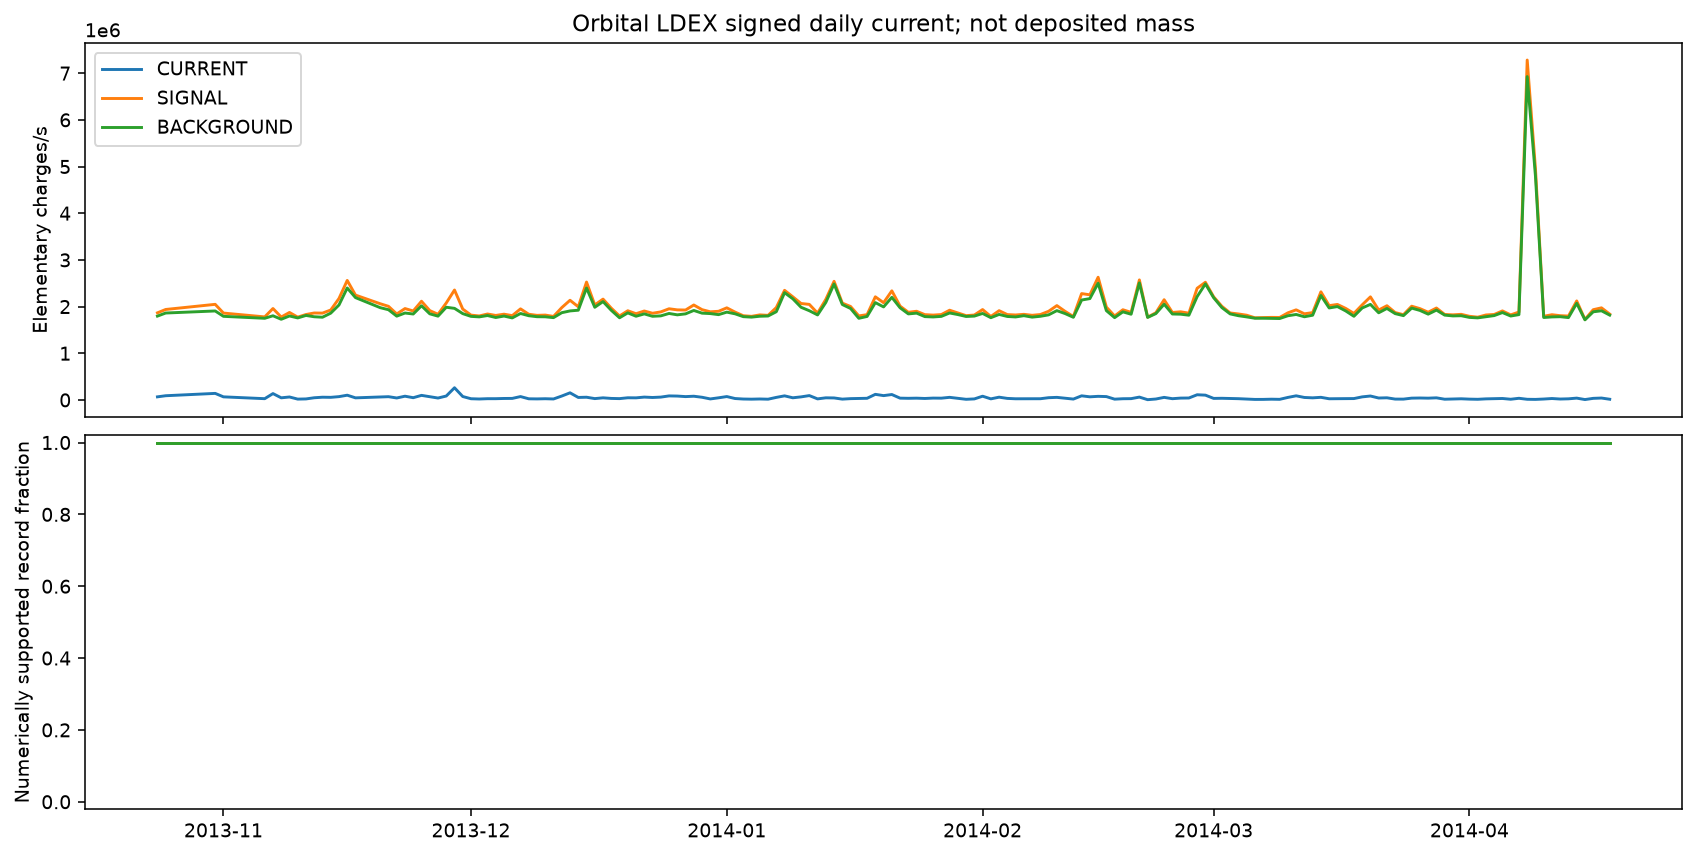

In [3]:
display(pd.read_csv(folder/'current_uncertainty_by_file.csv'))
display(Image(filename=str(folder/'signed_current_context.png')))

## Impact classes, saturation and changing native thresholds
Keep all quality classes visible. Numerical mass/threshold/uncertainty support does not replace the classification documentation or instrument live time, area and efficiency. Missing event dates are not inserted as zero-flux days.

,QUALITY,SATURATED,catalog_records
0,-2,0,240304
1,-2,1,5
2,-1,0,12452
3,1,0,5174
4,1,1,4
5,2,0,37791
6,2,1,3
7,3,0,135216
8,3,1,20
9,4,0,9194


,quality,saturated,field,catalog_records,below_native_mass_threshold,numerically_supported_unique_clock_records,valid,min,median,p95,max,scope
0,-2,0,MASS,240304,6346,236648,236648,3.550000e-33,5.894000e-16,1.097000e-15,2.015000e-14,"numerical/class-specific context, not event-cl..."
1,-2,0,MASS_THRESHOLD,240304,6346,236648,236648,2.075000e-16,2.436000e-16,2.474000e-16,2.481000e-16,"numerical/class-specific context, not event-cl..."
2,-2,0,MASS_SIG,240304,6346,236648,236648,2.230000e-17,5.057000e-17,8.485000e-17,1.530000e-15,"numerical/class-specific context, not event-cl..."
3,-2,0,mass_to_threshold,240304,6346,236648,236648,1.480277e-17,2.445582e+00,4.491115e+00,8.864936e+01,"numerical/class-specific context, not event-cl..."
4,-2,0,relative_reported_uncertainty,240304,6346,236648,236648,7.350664e-02,8.580667e-02,1.112131e-01,7.142857e+15,"numerical/class-specific context, not event-cl..."
...,...,...,...,...,...,...,...,...,...,...,...,...
79,5,1,MASS_THRESHOLD,4,0,4,4,2.021000e-16,2.072500e-16,2.232120e-15,2.589000e-15,"numerical/class-specific context, not event-cl..."
80,5,1,MASS_SIG,4,0,4,4,3.626000e-14,1.767900e-13,3.400850e-13,3.506000e-13,"numerical/class-specific context, not event-cl..."
81,5,1,mass_to_threshold,4,0,4,4,1.001159e+03,2.416241e+03,1.365539e+04,1.549096e+04,"numerical/class-specific context, not event-cl..."
82,5,1,relative_reported_uncertainty,4,0,4,4,1.082176e-01,1.100226e-01,1.110464e-01,1.111314e-01,"numerical/class-specific context, not event-cl..."


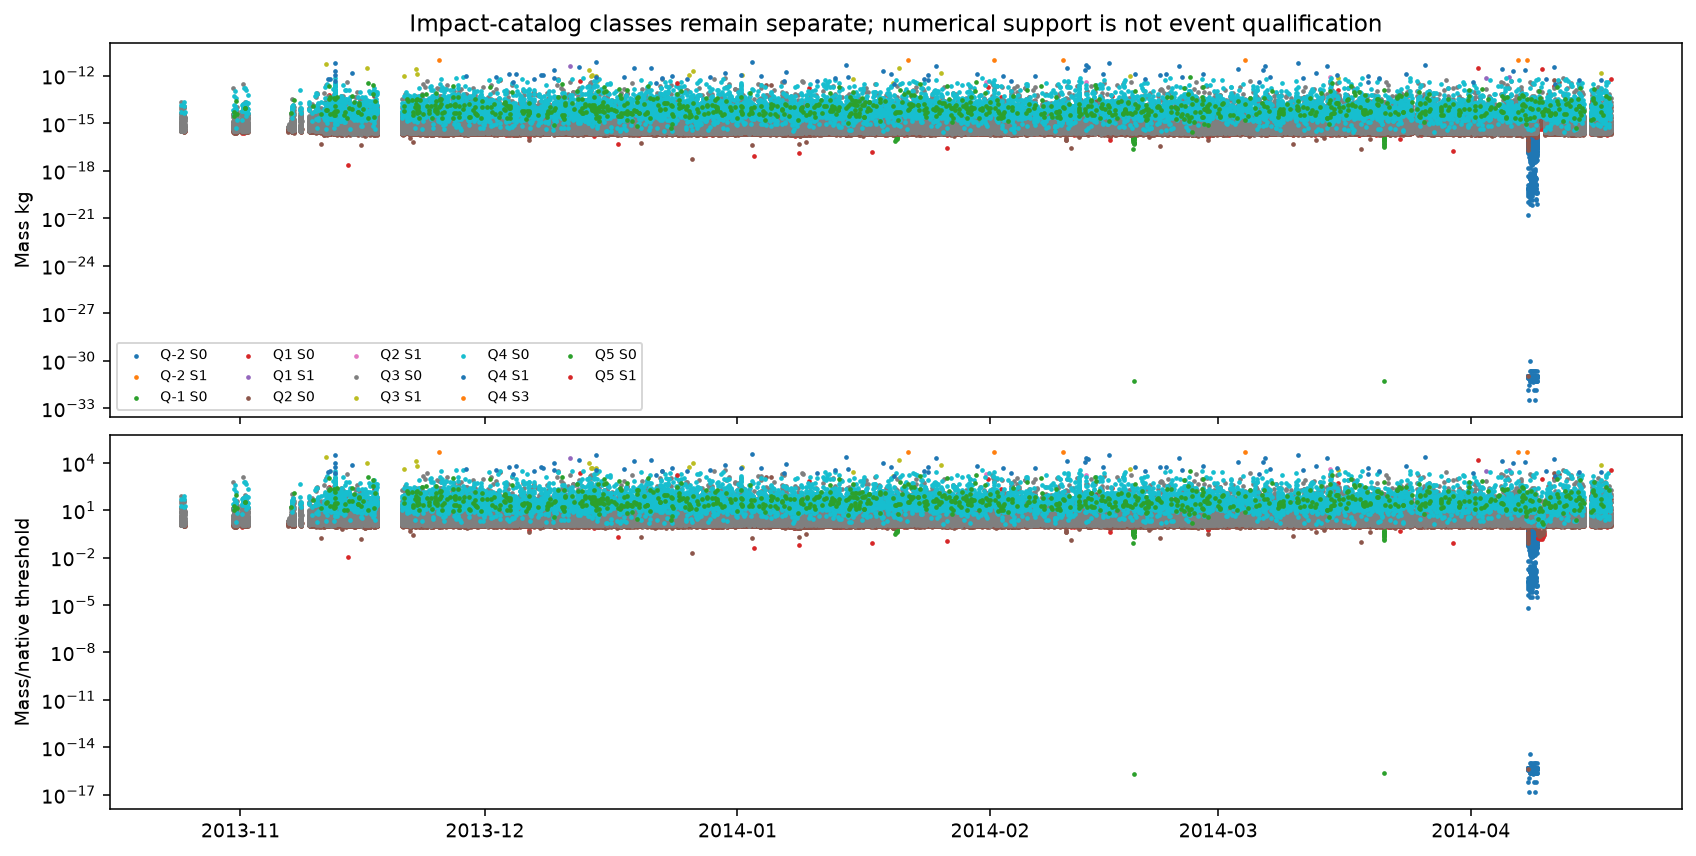

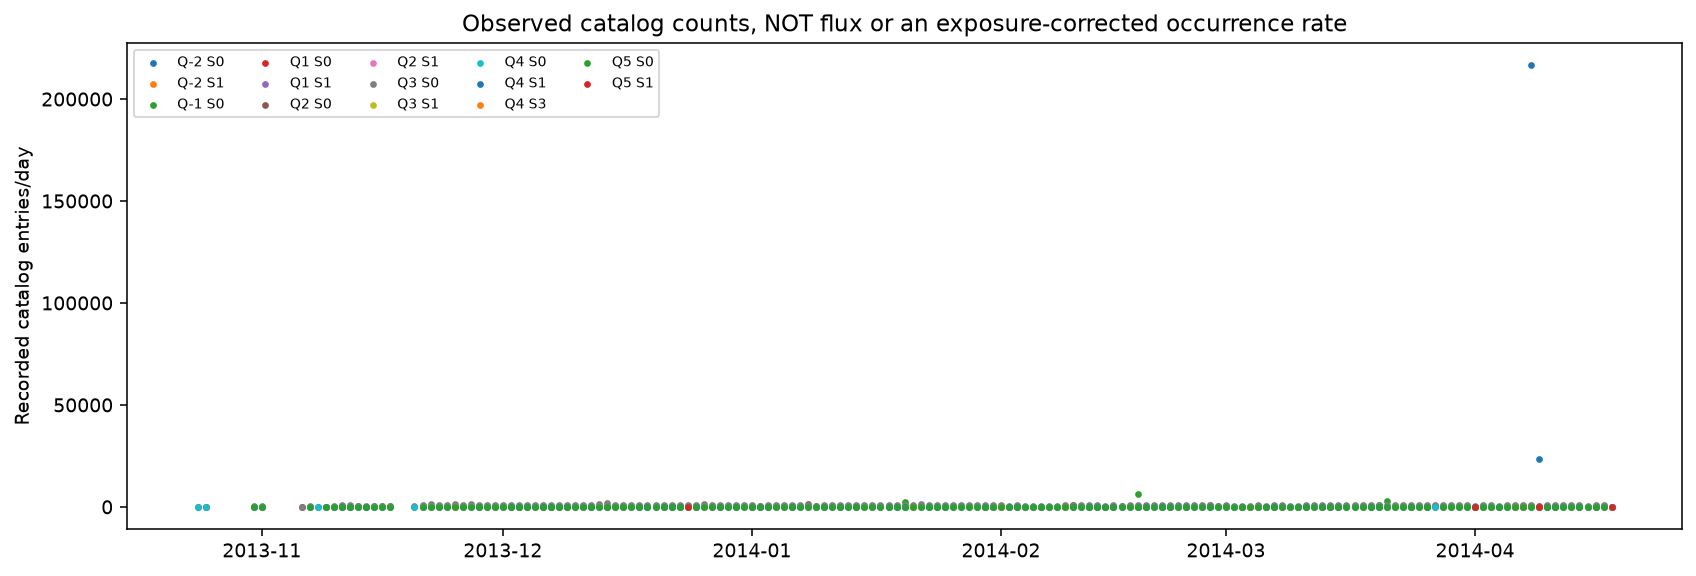

In [4]:
display(pd.read_csv(folder/'event_class_summary.csv'))
display(pd.read_csv(folder/'mass_threshold_summary.csv'))
for name in ['mass_threshold_classes','catalog_records_not_rates']: display(Image(filename=str(folder/(name+'.png'))))

## Calendar support and previous EDA cross-check
Month, quarter, four-month term, half-year, year, two-year and DJF/MAM/JJA/SON windows retain full calendar denominators and partial mission support. These are calendar labels, not lunar seasons or future risk forecasts. Mass-series sample totals count catalog detections, not instrument exposure.

In [5]:
display(pd.read_csv(folder/'calendar_context.csv').groupby('period_kind').size().rename('rows'))
checks=pd.read_csv(folder/'crosscheck_Dar044.csv')
display(checks.agg({'absolute_difference':'max','support_changed':'sum'}))
print('Matched original current/day rows:',len(checks))

period_kind
calendar_season     97
four_month_term     66
half_year           66
month              207
quarter             95
two_year            66
year                66
Name: rows, dtype: int64

absolute_difference    0.0
support_changed        0.0
dtype: float64

Matched original current/day rows: 498


## Stage 4 proposal and base conclusion
The data improves orbital dust/background and detection-support context. Applying it to local contamination, health or hardware requires activity/transport and qualified degradation/capability evidence. These proposals remain separate from Stage 5; operational conclusions are Unknown.

In [6]:
display(pd.read_csv(folder/'stage4_dust_proposals.csv')[['id','classification','title','current_outcome','decision_logic']])
print(json.dumps(findings,indent=2))
print('Completed run:',folder)

,id,classification,title,current_outcome,decision_logic
0,DU-G01,evidence_guard,"Impact classes, thresholds and saturation rema...",Unknown,No lowest/highest quality-number assumption; n...
1,DU-G02,evidence_guard,Counts and current are not flux or surface loa...,Unknown,Event-catalog record counts are not occurrence...
2,DU-H01,conditional_hard_constraint,"Essential cooling, sealing and filtration rema...",Unknown,Failed if qualified applicable demand exceeds ...
3,DU-S01,conditional_soft_preference,Lower qualified dust-maintenance burden,Unknown,"Prefer supported total operational burden, not..."
4,DU-G03,evidence_guard,Real historical duration and background uncert...,Unknown,Keep the 2013-2014 mission span; no fabricated...


{
  "subject": "dust",
  "sample": false,
  "analysed_files": 36,
  "current_records": 677271,
  "mass_catalog_records": 441166,
  "current_recorded_dates": 166,
  "mass_recorded_dates": 166,
  "ambiguous_current_clock_records": 0,
  "ambiguous_mass_clock_records": 0,
  "numerically_supported_mass_records": 437451,
  "numerical_mass_below_native_threshold": 9041,
  "time_start": "2013-10-24 17:43:38.548000+00:00",
  "time_stop": "2014-04-18 04:30:16.698000+00:00",
  "tables": {
    "current_daily_context": 1494,
    "current_uncertainty_by_file": 54,
    "event_class_summary": 14,
    "event_class_daily_records": 928,
    "mass_threshold_summary": 84,
    "calendar_context": 663,
    "matched_January_December_years": 66,
    "field_metadata": 306,
    "crosscheck_Dar044": 498,
    "stage4_dust_proposals": 5
  },
  "time_contract": "UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=Jan-Apr/May-Aug/Sep-Dec; DJF/MAM/JJA/SON are calendar